In [3]:
import pandas as pd
import numpy as np
from statistics import mean
import os
import sys

# Ruta absoluta al directorio src
src_path = os.path.abspath("../src")
sys.path.append(src_path)

# Ahora puedes importar el módulo utils
from utils.exploration_utils import preprocess_data, evaluar_escenarios_trading, sma_engineering_from_close
from utils.viz_utils import plot_candlestick_with_clusters_plotly 

pd.set_option('display.max_columns', None)


In [4]:
import importlib
import utils.exploration_utils
import utils.support_resistance
import utils.viz_utils
importlib.reload(utils.exploration_utils)
importlib.reload(utils.support_resistance)
importlib.reload(utils.viz_utils)

<module 'utils.viz_utils' from 'c:\\Users\\Administrador\\Documents\\Proyectos\\Trading\\ForexDataExtractorProject\\src\\utils\\viz_utils.py'>

In [5]:
def read_csv_files(folder_path):
    # List all CSV files in the folder
    all_files = os.listdir(folder_path)
    csv_files = [os.path.join(folder_path, file) for file in all_files if file.endswith('.csv')]
    
    # Read and concatenate all CSV files into a single DataFrame
    combined_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
    
    return combined_df

In [6]:
# Read Data:
# folder_path = '../data/EURUSD/5mins'
# df_EURUSD_5min = read_csv_files(folder_path)
# df_EURUSD_5min = preprocess_data(df_EURUSD_5min)


# Read Data from parquet file:
df_EURUSD_5min = pd.read_parquet('../data/parquet/EURUSD/EURUSD_5mins.parquet')


In [7]:
# # Read Data:
# folder_path = '../data/EURUSD/1min'
# df_EURUSD_1min = read_csv_files(folder_path)
# df_EURUSD_1min = preprocess_data(df_EURUSD_1min)



# Read Data from parquet file:
df_EURUSD_1min = pd.read_parquet('../data/parquet/EURUSD/EURUSD_1min.parquet')


In [8]:
import importlib
import utils.exploration_utils
import utils.support_resistance
import utils.viz_utils
importlib.reload(utils.exploration_utils)
importlib.reload(utils.support_resistance)
importlib.reload(utils.viz_utils)

<module 'utils.viz_utils' from 'c:\\Users\\Administrador\\Documents\\Proyectos\\Trading\\ForexDataExtractorProject\\src\\utils\\viz_utils.py'>

In [9]:
import matplotlib.dates as mdates
from utils.support_resistance import calculate_progressive_support_resistance, calcular_metricas_fila

In [ ]:
# Probar con un subconjunto pequeño primero

history_df, df_with_levels = calculate_progressive_support_resistance(
    df=df_EURUSD_5min,                   # DataFrame con datos OHLC
    initial_window=100,                  # Ventana inicial de análisis
    step_size=100,                       # Procesar cada 100 velas para eficiencia
    lookback_window=100,                 # Ventana de análisis para soportes y resistencias
    prominence=0.0005,                   # Filtro para detección de picos
    distance=3,                         # Distancia mínima entre picos
    pips_range=0.0002,                   # Rango para agrupar picos (1 pip en EUR/USD)
    reaction_window=10,    
    merge_threshold=0.0003,              # Umbral para fusionar niveles
    add_relevant_levels = True
)


Iniciando procesamiento progresivo con 1030464 velas.

--- DEBUG REACTION MAGNITUDE PARA NIVEL 1.438050 ---
Tipo predominante: R
Índice máximo: 136
Ventana de reacción: 137 a 147
¿Hay datos futuros? Sí
Precios futuros: [1.43775 1.43735 1.43815 1.4395  1.43905]...
Min futuro: 1.437350, Max futuro: 1.439500
Precio medio del nivel: 1.438050
Cálculo (R): 1.438050 - 1.437350 = 0.000700
Magnitud final (max con 0): 0.000700
-----------------------------------


--- DEBUG REACTION MAGNITUDE PARA NIVEL 1.437950 ---
Tipo predominante: R
Índice máximo: 723
Ventana de reacción: 724 a 734
¿Hay datos futuros? Sí
Precios futuros: [1.43615 1.4366  1.43585 1.43615 1.4362 ]...
Min futuro: 1.435250, Max futuro: 1.436600
Precio medio del nivel: 1.437950
Cálculo (R): 1.437950 - 1.435250 = 0.002700
Magnitud final (max con 0): 0.002700
-----------------------------------


--- DEBUG REACTION MAGNITUDE PARA NIVEL 1.438300 ---
Tipo predominante: R
Índice máximo: 710
Ventana de reacción: 711 a 721
¿Hay datos fu

KeyboardInterrupt: 

In [ ]:

# Create the directory path if it doesn't exist
parquet_folder = '../data/parquet/EURUSD/'
os.makedirs(parquet_folder, exist_ok=True)

# Save DataFrame as parquet file
parquet_path = os.path.join(parquet_folder, 'EURUSD_5mins_sr_levels.parquet')
df_with_levels.to_parquet(parquet_path, index=False)

print(f"DataFrame saved as parquet file at: {parquet_path}")

DataFrame saved as parquet file at: ../data/parquet/EURUSD/EURUSD_5mins_sr_levels.parquet


In [10]:
df_EURUSD_5min = pd.read_parquet('../data/parquet/EURUSD/EURUSD_5mins_sr_levels.parquet')

In [11]:
df_EURUSD_5min.shape

(1030464, 15)

In [12]:
import json

# Obtener el JSON desde la celda del dataframe
json_str = df_EURUSD_5min.iloc[1030463]['relevant_levels']

# Convertir a diccionario Python
levels_dict = json.loads(json_str)

# Mostrar de forma estructurada con indentación
print(json.dumps(levels_dict, indent=2))

{
  "closest": [
    {
      "id": 1034,
      "price": 1.064318112244898,
      "type": "Resistencia",
      "touch_count": 196,
      "distance": 0.0001181122448978833,
      "bars_since_touch": 84,
      "last_touch": "2024-04-12 09:55:00",
      "reaction_magnitude": 0.007600000000000051,
      "prominence": 0.0011956632653061221,
      "duration": 654825,
      "importance_score": 36.88083400794265
    },
    {
      "id": 1004,
      "price": 1.0638847222222216,
      "type": "Soporte",
      "touch_count": 180,
      "distance": 0.00031527777777839994,
      "bars_since_touch": 95,
      "last_touch": "2024-04-12 09:00:00",
      "reaction_magnitude": 0.015025000000000066,
      "prominence": 0.0011633333333333441,
      "duration": 655097,
      "importance_score": 41.36684547162193
    }
  ],
  "recent": [
    {
      "id": 1074,
      "price": 1.0627243902439032,
      "type": "Resistencia",
      "touch_count": 164,
      "distance": 0.0014756097560968406,
      "bars_since_

In [13]:

# Si no lo está, asegúrate de convertirlo:
# EURUSD_5mins_sr_levels['datetime'] = pd.to_datetime(EURUSD_5mins_sr_levels['datetime'])

# Aplicar la función a cada fila y obtener un DataFrame con las nuevas columnas
nuevas_metricas = df_EURUSD_5min.apply(calcular_metricas_fila, axis=1)

# Combinar las nuevas columnas con el DataFrame original (opcional)
df_resultado = pd.concat([df_EURUSD_5min, nuevas_metricas], axis=1)

# Mostrar las primeras filas para verificar
print(df_resultado.head())


                           date     open     high      low    close  volume  \
0  20100103 17:15:00 US/Eastern  1.43085  1.43090  1.43080  1.43090      -1   
1  20100103 17:20:00 US/Eastern  1.43090  1.43175  1.43090  1.43170      -1   
2  20100103 17:25:00 US/Eastern  1.43170  1.43180  1.43150  1.43170      -1   
3  20100103 17:30:00 US/Eastern  1.43170  1.43180  1.43095  1.43110      -1   
4  20100103 17:35:00 US/Eastern  1.43110  1.43285  1.43110  1.43245      -1   

   barCount                  datetime  Year   Month  Day      Date  Hour  \
0        -1 2010-01-03 17:15:00-05:00  2010  201001    3  20100103    17   
1        -1 2010-01-03 17:20:00-05:00  2010  201001    3  20100103    17   
2        -1 2010-01-03 17:25:00-05:00  2010  201001    3  20100103    17   
3        -1 2010-01-03 17:30:00-05:00  2010  201001    3  20100103    17   
4        -1 2010-01-03 17:35:00-05:00  2010  201001    3  20100103    17   

   Minute                relevant_levels direccion_ultimo  fuerza_ul

In [14]:
df_resultado.shape

(1030464, 29)

In [15]:
# Get the reference datetime
reference_data = df_EURUSD_5min.query("datetime >= '2024-04-01 14:50:00-05:00'")



In [16]:
import plotly.graph_objects as go

# Agregar velas (candlestick)
fig = go.Figure(
    data=[
        go.Candlestick(  
            x=reference_data['datetime'],
            open=reference_data['open'],
            high=reference_data['high'],
            low=reference_data['low'],
            close=reference_data['close'],
        )
        ]
    )

fig.update_layout(
    title="Niveles de clusters por masa",
    xaxis_title="Fecha",
    yaxis_title="Precio",
    xaxis_rangeslider_visible=False
)



fig.show()

In [17]:
reference_data

from numpy.lib.stride_tricks import sliding_window_view

X = 24
# Create sliding window view of future close values
future_high_values = sliding_window_view(df_resultado['high'].values, window_shape=X)
future_low_values = sliding_window_view(df_resultado['low'].values, window_shape=X)
future_close_values = sliding_window_view(df_resultado['close'].values, window_shape=X)

# Pad with NaN at the end since we can't look into the future for the last X-1 rows

padding = np.full((X-1, X), np.nan)
future_high_values = np.vstack([future_high_values, padding])
future_low_values = np.vstack([future_low_values, padding])
future_close_values = np.vstack([future_close_values, padding])

# Assign to DataFrame
df_resultado['future_high_values'] = future_high_values.tolist()
df_resultado['future_low_values'] = future_low_values.tolist()
df_resultado['future_close_values'] = future_close_values.tolist()

# Mostrar las primeras filas para verificar
df_resultado.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,relevant_levels,direccion_ultimo,fuerza_ultimo,comportamiento,posicion_precio_recent,pips_desde_ultimo,minutos_desde_ultimo_touch,tendencia_recent,pips_cercano,minutos_desde_cercano,nivel_en_recent,posicion_nivel_cercano,fuerza_nivel_cercano,pips_nivel_arriba,pips_nivel_abajo,future_high_values,future_low_values,future_close_values
0,20100103 17:15:00 US/Eastern,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"{""closest"": [], ""recent"": []}",None,NaN,None,NaN,NaN,NaN,None,NaN,NaN,None,None,NaN,NaN,NaN,"[1.4309, 1.43175, 1.4318, 1.4318, 1.43285, 1.4...","[1.4308, 1.4309, 1.4315, 1.43095, 1.4311, 1.43...","[1.4309, 1.4317, 1.4317, 1.4311, 1.43245, 1.43..."
1,20100103 17:20:00 US/Eastern,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"{""closest"": [], ""recent"": []}",None,NaN,None,NaN,NaN,NaN,None,NaN,NaN,None,None,NaN,NaN,NaN,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4..."
2,20100103 17:25:00 US/Eastern,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"{""closest"": [], ""recent"": []}",None,NaN,None,NaN,NaN,NaN,None,NaN,NaN,None,None,NaN,NaN,NaN,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4..."
3,20100103 17:30:00 US/Eastern,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"{""closest"": [], ""recent"": []}",None,NaN,None,NaN,NaN,NaN,None,NaN,NaN,None,None,NaN,NaN,NaN,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4..."
4,20100103 17:35:00 US/Eastern,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"{""closest"": [], ""recent"": []}",None,NaN,None,NaN,NaN,NaN,None,NaN,NaN,None,None,NaN,NaN,NaN,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1...."


In [18]:
df_resultado.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'barCount',
       'datetime', 'Year', 'Month', 'Day', 'Date', 'Hour', 'Minute',
       'relevant_levels', 'direccion_ultimo', 'fuerza_ultimo',
       'comportamiento', 'posicion_precio_recent', 'pips_desde_ultimo',
       'minutos_desde_ultimo_touch', 'tendencia_recent', 'pips_cercano',
       'minutos_desde_cercano', 'nivel_en_recent', 'posicion_nivel_cercano',
       'fuerza_nivel_cercano', 'pips_nivel_arriba', 'pips_nivel_abajo',
       'future_high_values', 'future_low_values', 'future_close_values'],
      dtype='object')

In [19]:
df_resultado[['compra_resultado', 'compra_velas', 'compra_pips',
        'venta_resultado', 'venta_velas', 'venta_pips']] = df_resultado.apply(
    lambda row: evaluar_escenarios_trading(row, pips_objetivo=10, pips_stop=3),
    axis=1
)

In [20]:
df_resultado.shape

(1030464, 38)

In [21]:
print(df_resultado.iloc[1]['close'])
print("-------ESCENARIO COMPRA-------")

print(df_resultado.iloc[1]['close']+20/10000)
print(df_resultado.iloc[1]['close']-5/10000)

print("-------ESCENARIO VENTA-------")
print(df_resultado.iloc[1]['close']-20/10000)
print(df_resultado.iloc[1]['close']+5/10000)

print("-------VALORES FUTUROS-------")
print(df_resultado.iloc[1]['future_high_values'])
print(df_resultado.iloc[1]['future_low_values'])

1.4317
-------ESCENARIO COMPRA-------
1.4337
1.4312
-------ESCENARIO VENTA-------
1.4297
1.4322
-------VALORES FUTUROS-------
[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1.43375, 1.43265, 1.433, 1.43345, 1.4333, 1.43315, 1.43315, 1.43245, 1.43285, 1.4334, 1.4329, 1.4329, 1.432, 1.43165, 1.43115, 1.43085, 1.4303]
[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1.43225, 1.43235, 1.43285, 1.43245, 1.43285, 1.4323, 1.43215, 1.4324, 1.43285, 1.43265, 1.43185, 1.43165, 1.4304, 1.42965, 1.429, 1.42895]


In [22]:
df_EURUSD_5min = df_resultado.copy()
# Calculate counts
counts = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts()

# Calculate percentages
percentages = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts(normalize=True) * 100

# Combine counts and percentages
results = pd.DataFrame({
    'Count': counts,
    'Percentage': percentages.round(2)
})

print(results)

                                        Count  Percentage
compra_resultado   venta_resultado                       
STOP_ALCANZADO     STOP_ALCANZADO      594939       57.74
OBJETIVO_ALCANZADO STOP_ALCANZADO      144813       14.05
STOP_ALCANZADO     OBJETIVO_ALCANZADO  141988       13.78
SIN_ALCANCE        STOP_ALCANZADO       71178        6.91
STOP_ALCANZADO     SIN_ALCANCE          67925        6.59
SIN_ALCANCE        SIN_ALCANCE           9621        0.93


In [23]:
df_EURUSD_5min.shape

(1030464, 38)

In [24]:
# Create two filtered dataframes
compra_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['compra_resultado'] == 'SIN_ALCANCE']
venta_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['venta_resultado'] == 'SIN_ALCANCE']

print(compra_sin_alcance.compra_pips.mean())
print(venta_sin_alcance.venta_pips.mean())


2.734073239576112
2.6266398359196628


In [25]:
sr_cols = [ 'direccion_ultimo', 'fuerza_ultimo',
       'comportamiento', 'posicion_precio_recent', 'pips_desde_ultimo',
       'minutos_desde_ultimo_touch', 'tendencia_recent', 'pips_cercano',
       'minutos_desde_cercano', 'nivel_en_recent', 'posicion_nivel_cercano',
       'fuerza_nivel_cercano', 'pips_nivel_arriba', 'pips_nivel_abajo']
df_EURUSD_5min[sr_cols].describe()

,fuerza_ultimo,posicion_precio_recent,pips_desde_ultimo,minutos_desde_ultimo_touch,pips_cercano,minutos_desde_cercano,fuerza_nivel_cercano,pips_nivel_arriba,pips_nivel_abajo
count,1.030365e+06,1.030365e+06,1.030365e+06,1.030365e+06,1.030365e+06,1.030365e+06,1.030365e+06,9.321430e+05,9.280610e+05
mean,3.467460e+01,3.983873e+00,2.132388e+01,9.327271e+01,1.189734e+00,6.289856e+03,3.427274e+01,2.067914e+00,1.972776e+00
std,1.291848e+01,2.253411e+00,2.328468e+01,1.382913e+02,2.746641e+00,3.290270e+04,1.286952e+01,2.855890e+00,1.567561e+00
min,1.699455e+00,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.349120e+00,1.110223e-12,1.110223e-12
25%,2.656881e+01,2.000000e+00,6.863924e+00,3.700000e+01,5.100000e-01,9.300000e+01,2.597893e+01,9.266180e-01,9.311024e-01
50%,3.613828e+01,4.000000e+00,1.442767e+01,6.400000e+01,1.021978e+00,2.330000e+02,3.571449e+01,1.851064e+00,1.864078e+00
75%,4.403381e+01,6.000000e+00,2.740164e+01,9.200000e+01,1.545455e+00,1.133000e+03,4.374059e+01,2.878855e+00,2.886792e+00
max,7.560011e+01,7.000000e+00,4.385076e+02,1.348000e+03,1.988333e+02,7.623310e+05,8.341259e+01,1.988333e+02,1.325000e+02


In [26]:
df_EURUSD_5min["multiclass_target"] = np.where(
    (df_EURUSD_5min['compra_resultado'] == 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] != 'OBJETIVO_ALCANZADO'),
    'objetivo_compra_alcanzado',
    np.where(
        (df_EURUSD_5min['compra_resultado'] != 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] == 'OBJETIVO_ALCANZADO'),
        'objetivo_venta_alcanzado',
        'no_objetivo_alcanzado'
    )
)

In [27]:
import utils.exploration_utils
importlib.reload(utils.exploration_utils)


<module 'utils.exploration_utils' from 'c:\\Users\\Administrador\\Documents\\Proyectos\\Trading\\ForexDataExtractorProject\\src\\utils\\exploration_utils.py'>

In [28]:
from utils.exploration_utils import sma_engineering_from_close
df_EURUSD_5min = sma_engineering_from_close(df_EURUSD_5min, [10,40,100])

In [29]:
from utils.exploration_utils import feature_engineering_rsi
df_EURUSD_5min = feature_engineering_rsi(df_EURUSD_5min)

In [30]:
from utils.exploration_utils import bollinger_bands_engineering
df_EURUSD_5min = bollinger_bands_engineering(df_EURUSD_5min, periods=[20, 50], std_devs=[2.0, 2.5])

In [31]:
from utils.exploration_utils import macd_engineering

# Or customize the parameters
df_EURUSD_5min = macd_engineering(
    df=df_EURUSD_5min, 
    fast_periods=[12, 8],    # Multiple fast periods
    slow_periods=[26, 21],   # Multiple slow periods
    signal_periods=[9],      # Signal line period
    close_col='close',       # Column with close prices
    lookback=5               # For momentum calculations
)

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:863: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:870: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:875: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

In [32]:
from utils.exploration_utils import atr_engineering

df_EURUSD_5min = atr_engineering(
    df=df_EURUSD_5min,
    periods=[14, 21],    # Multiple ATR periods
    lookback=5           # For trend analysis
)

In [33]:
from utils.exploration_utils import adx_engineering


df_EURUSD_5min = adx_engineering(
    df=df_EURUSD_5min,
    periods=[14, 21],    # Multiple ADX periods
    lookback=5           # For trend analysis
)

In [34]:
from utils.exploration_utils import stochastic_engineering
df_EURUSD_5min = stochastic_engineering(df_EURUSD_5min, k_periods=[14, 21], d_periods=[3, 5], lookback=5, slow=True)

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:702: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:703: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

c:\Users\Administrador\Documents\Proyectos\Trading\ForexDataExtractorProject\src\utils\exploration_utils.py:706: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

In [35]:
#from utils.exploration_utils import cci_engineering
#df_EURUSD_5min = cci_engineering(df_EURUSD_5min)

In [36]:
from utils.exploration_utils import parabolic_sar_engineering
df_EURUSD_5min = parabolic_sar_engineering(df_EURUSD_5min)

In [37]:
#from utils.exploration_utils import fractal_engineering
#df_EURUSD_5min = fractal_engineering(df_EURUSD_5min)

In [38]:
from utils.exploration_utils import round_number_pivot_engineering
df_EURUSD_5min = round_number_pivot_engineering(df_EURUSD_5min)

In [39]:
from utils.exploration_utils import calcular_features_vela
df_EURUSD_5min = calcular_features_vela(df_EURUSD_5min)

In [40]:
features = ['body_size', 'upper_wick', 'lower_wick', 'total_range', 
            'body_ratio', 'upper_wick_ratio', 'lower_wick_ratio']
          
from utils.exploration_utils import create_candle_features_vector
df_EURUSD_5min = create_candle_features_vector(df_EURUSD_5min, feature_columns=features, n_candles=6)

In [41]:
df_EURUSD_5min.dropna(inplace=True)

In [42]:
df_EURUSD_5min.shape

(829839, 639)

In [43]:
df_EURUSD_5min.columns.values

array(['date', 'open', 'high', 'low', 'close', 'volume', 'barCount',
       'datetime', 'Year', 'Month', 'Day', 'Date', 'Hour', 'Minute',
       'relevant_levels', 'direccion_ultimo', 'fuerza_ultimo',
       'comportamiento', 'posicion_precio_recent', 'pips_desde_ultimo',
       'minutos_desde_ultimo_touch', 'tendencia_recent', 'pips_cercano',
       'minutos_desde_cercano', 'nivel_en_recent',
       'posicion_nivel_cercano', 'fuerza_nivel_cercano',
       'pips_nivel_arriba', 'pips_nivel_abajo', 'future_high_values',
       'future_low_values', 'future_close_values', 'compra_resultado',
       'compra_velas', 'compra_pips', 'venta_resultado', 'venta_velas',
       'venta_pips', 'multiclass_target', 'SMA_10', 'SMA_40', 'SMA_100',
       'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100',
       'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100',
       'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score',
   

In [44]:
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
import numpy as np

# 1. Dividir los datos en entrenamiento y prueba basados en la fecha
df_train = df_EURUSD_5min[df_EURUSD_5min['Date'] < "20220101"]
df_test = df_EURUSD_5min[df_EURUSD_5min['Date'] >= "20220101"]

# 2. PRIMER CLUSTERING: Con características históricas (actual)
# Características para el clustering con datos históricos
features_historico = ['body_size', 'upper_wick', 'lower_wick', 'total_range',
       'body_ratio', 'upper_wick_ratio', 'lower_wick_ratio',
       'body_size_lag1', 'body_size_lag2', 'body_size_lag3',
       'body_size_lag4', 'body_size_lag5', 'body_size_lag6',
       'upper_wick_lag1', 'upper_wick_lag2', 'upper_wick_lag3',
       'upper_wick_lag4', 'upper_wick_lag5', 'upper_wick_lag6',
       'lower_wick_lag1', 'lower_wick_lag2', 'lower_wick_lag3',
       'lower_wick_lag4', 'lower_wick_lag5', 'lower_wick_lag6',
       'total_range_lag1', 'total_range_lag2', 'total_range_lag3',
       'total_range_lag4', 'total_range_lag5', 'total_range_lag6',
       'body_ratio_lag1', 'body_ratio_lag2', 'body_ratio_lag3',
       'body_ratio_lag4', 'body_ratio_lag5', 'body_ratio_lag6',
       'upper_wick_ratio_lag1', 'upper_wick_ratio_lag2',
       'upper_wick_ratio_lag3', 'upper_wick_ratio_lag4',
       'upper_wick_ratio_lag5', 'upper_wick_ratio_lag6',
       'lower_wick_ratio_lag1', 'lower_wick_ratio_lag2',
       'lower_wick_ratio_lag3', 'lower_wick_ratio_lag4',
       'lower_wick_ratio_lag5', 'lower_wick_ratio_lag6']

# 3. SEGUNDO CLUSTERING: Solo con características de la vela actual
# Definir las características de la vela actual (sin sufijos _lag)
features_actuales = ['body_size', 'upper_wick', 'lower_wick', 'total_range',
                    'body_ratio', 'upper_wick_ratio', 'lower_wick_ratio']

print(f"Filas en entrenamiento antes de procesar NaNs: {len(df_train)}")
print(f"Filas en prueba antes de procesar NaNs: {len(df_test)}")

# Crear y ajustar imputadores para ambos conjuntos de características
imputer_historico = SimpleImputer(strategy='mean')
imputer_actual = SimpleImputer(strategy='mean')

# Preparar datos para el clustering histórico
X_train_historico = df_train[features_historico].copy()
imputer_historico.fit(X_train_historico)

X_train_historico_imputed = imputer_historico.transform(X_train_historico)
X_test_historico_imputed = imputer_historico.transform(df_test[features_historico].copy())

# Preparar datos para el clustering de vela actual
X_train_actual = df_train[features_actuales].copy()
imputer_actual.fit(X_train_actual)

X_train_actual_imputed = imputer_actual.transform(X_train_actual)
X_test_actual_imputed = imputer_actual.transform(df_test[features_actuales].copy())

# Entrenar modelos KMeans
# Para el clustering histórico
kmeans_historico = KMeans(n_clusters=10, random_state=42)
kmeans_historico.fit(X_train_historico_imputed)

# Para el clustering de vela actual
kmeans_actual = KMeans(n_clusters=3, random_state=42)  # Menos clusters por ser menos dimensiones
kmeans_actual.fit(X_train_actual_imputed)

# Predecir los clusters para ambos conjuntos
# Clustering histórico
train_clusters_historico = kmeans_historico.predict(X_train_historico_imputed)
test_clusters_historico = kmeans_historico.predict(X_test_historico_imputed)

# Clustering de vela actual
train_clusters_actual = kmeans_actual.predict(X_train_actual_imputed)
test_clusters_actual = kmeans_actual.predict(X_test_actual_imputed)

# Asignar los clusters a cada conjunto por separado
df_train_with_clusters = df_train.copy()
df_test_with_clusters = df_test.copy()

# Convertir los clusters a tipo string/categórico
df_train_with_clusters['cluster'] = train_clusters_historico.astype(str)
df_test_with_clusters['cluster'] = test_clusters_historico.astype(str)

# Añadir los nuevos clusters de vela actual
df_train_with_clusters['candle_cluster'] = train_clusters_actual.astype(str)
df_test_with_clusters['candle_cluster'] = test_clusters_actual.astype(str)

# Combinar ambos conjuntos manteniendo el orden cronológico
df_EURUSD_5min_with_clusters = pd.concat([df_train_with_clusters, df_test_with_clusters])

# Verificar que el orden y los índices se han mantenido correctamente
if len(df_EURUSD_5min) == len(df_EURUSD_5min_with_clusters):
    # Si todo está correcto, actualizamos el DataFrame original
    df_EURUSD_5min = df_EURUSD_5min_with_clusters
    
    # Mostrar distribuciones de ambos clusterings
    print(f"\nDistribución de clusters históricos en entrenamiento:")
    print(df_train_with_clusters['cluster'].value_counts().sort_index())
    
    print(f"\nDistribución de clusters de vela actual en entrenamiento:")
    print(df_train_with_clusters['candle_cluster'].value_counts().sort_index())
    
    print(f"\nDistribución de clusters históricos en prueba:")
    print(df_test_with_clusters['cluster'].value_counts().sort_index())
    
    print(f"\nDistribución de clusters de vela actual en prueba:")
    print(df_test_with_clusters['candle_cluster'].value_counts().sort_index())
    
    # Verificar relación entre ambos clusterings
    print("\nTabla de contingencia entre ambos tipos de clusters:")
    print(pd.crosstab(df_EURUSD_5min['cluster'], df_EURUSD_5min['candle_cluster']))
else:
    print("Error: El número de filas no coincide después de la combinación.")

Filas en entrenamiento antes de procesar NaNs: 696503
Filas en prueba antes de procesar NaNs: 133336


e:\Programas\envs\Autotrader\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning

e:\Programas\envs\Autotrader\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning




Distribución de clusters históricos en entrenamiento:
cluster
0    74474
1    64000
2    61254
3    74288
4    72416
5    63583
6    65342
7    74141
8    74546
9    72459
Name: count, dtype: int64

Distribución de clusters de vela actual en entrenamiento:
candle_cluster
0    316702
1    211825
2    167976
Name: count, dtype: int64

Distribución de clusters históricos en prueba:
cluster
0    14689
1    11930
2    11302
3    14440
4    13789
5    12431
6    12554
7    14184
8    14196
9    13821
Name: count, dtype: int64

Distribución de clusters de vela actual en prueba:
candle_cluster
0    60557
1    41356
2    31423
Name: count, dtype: int64

Tabla de contingencia entre ambos tipos de clusters:
candle_cluster      0      1      2
cluster                            
0               54005  19466  15692
1               34459  22410  19061
2               46311  14524  11721
3                8694  44984  35050
4               62004  13215  10986
5               15871  33872  26271
6    

In [45]:
import importlib
importlib.reload(utils.exploration_utils)
import utils.exploration_utils

In [46]:
from utils.exploration_utils import create_basic_patterns, create_pattern_mapping, apply_pattern_mapping



# 1. Volver a obtener los conjuntos de entrenamiento y prueba
df_train = df_EURUSD_5min[df_EURUSD_5min['Date'] < "20220101"]
df_test = df_EURUSD_5min[df_EURUSD_5min['Date'] >= "20220101"]

# 2. Crear los patrones básicos para ambos conjuntos
train_patterns = create_basic_patterns(df_train, cluster_column='candle_cluster', n_candles=5)
test_patterns = create_basic_patterns(df_test, cluster_column='candle_cluster', n_candles=5)

# 3. Crear el mapeo de patrones usando SOLO los datos de entrenamiento
# Esto evita la fuga de información del conjunto de prueba
pattern_mapping = create_pattern_mapping(
    patterns=train_patterns, 
    min_threshold=500,  # Ajustar según necesidad
    similarity_method='hamming'  # O 'edit' si se prefiere
)

# 4. Aplicar el mapeo a ambos conjuntos
train_patterns_mapped = apply_pattern_mapping(train_patterns, pattern_mapping)
test_patterns_mapped = apply_pattern_mapping(test_patterns, pattern_mapping)

# 5. Asignar los patrones de vuelta a los DataFrames originales
df_train.loc[:, 'pattern'] = train_patterns_mapped
df_test.loc[:, 'pattern'] = test_patterns_mapped

# 6. Combinar los DataFrames preservando la columna de patrones
df_EURUSD_5min = pd.concat([df_train, df_test])

# 7. Mostrar las estadísticas de los patrones
print("Distribución de patrones en el conjunto de entrenamiento:")
print(train_patterns_mapped.value_counts().head(10))
print("\nDistribución de patrones en el conjunto de prueba:")
print(test_patterns_mapped.value_counts().head(10))

# 8. Mostrar cuántos patrones raros fueron mapeados
patrones_originales = len(train_patterns.unique())
patrones_final = len(train_patterns_mapped.unique())
print(f"\nPatrones únicos en entrenamiento: {patrones_originales} originales → {patrones_final} después del mapeo")
print(f"Patrones únicos en prueba: {len(test_patterns_mapped.unique())} (incluyendo 'other_pattern' si existe)")

C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\4280885430.py:26: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\4280885430.py:26: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\4280885430.py:27: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(ax

Distribución de patrones en el conjunto de entrenamiento:
candle_cluster
0_0_0_0_0    14972
1_0_0_0_0     9433
0_0_0_0_1     9385
0_1_0_0_0     9028
0_0_1_0_0     9014
0_0_0_1_0     8991
0_0_0_0_2     7362
2_0_0_0_0     7314
0_2_0_0_0     7137
0_0_2_0_0     7032
Name: count, dtype: int64

Distribución de patrones en el conjunto de prueba:
candle_cluster
0_0_0_0_0    2686
1_0_0_0_0    1801
0_1_0_0_0    1776
0_0_0_1_0    1776
0_0_0_0_1    1771
0_0_1_0_0    1731
0_2_0_0_0    1413
0_0_0_0_2    1374
0_0_2_0_0    1370
2_0_0_0_0    1344
Name: count, dtype: int64

Patrones únicos en entrenamiento: 248 originales → 244 después del mapeo
Patrones únicos en prueba: 248 (incluyendo 'other_pattern' si existe)


In [47]:
df_EURUSD_5min['pattern'].value_counts()

pattern
0_0_0_0_0                17658
1_0_0_0_0                11234
0_0_0_0_1                11156
0_1_0_0_0                10804
0_0_0_1_0                10767
                         ...  
other_pattern                4
1_None_None_None_None        1
0_1_None_None_None           1
1_0_1_None_None              1
1_1_0_1_None                 1
Name: count, Length: 248, dtype: int64

In [48]:
#from utils.exploration_utils import create_pca_features
#df_EURUSD_5min = create_pca_features(df_EURUSD_5min, features, n_components=7,  window_size=5)

In [49]:
from utils.exploration_utils import create_candle_patterns
df_EURUSD_5min['pattern_2'] = create_candle_patterns(df_EURUSD_5min, 'candle_cluster', 3)

C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\1863909795.py:2: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



In [50]:
df_EURUSD_5min['pattern_2'].value_counts()

pattern_2
0_0_0            80187
1_0_0            52199
0_0_1            52195
0_1_0            51296
0_0_2            41086
2_0_0            41082
0_2_0            40769
1_1_0            36618
0_1_1            36568
1_0_1            34608
1_0_2            27125
2_0_1            26986
1_1_1            26941
0_2_1            26081
2_1_0            26018
0_1_2            25926
1_2_0            25805
2_2_0            23284
0_2_2            23150
2_0_2            21789
2_1_1            18124
1_1_2            18074
1_2_1            16913
1_2_2            14898
2_2_1            14764
2_2_2            13735
2_1_2            13616
other_pattern        2
Name: count, dtype: int64

In [51]:
df_EURUSD_5min.columns.values

array(['date', 'open', 'high', 'low', 'close', 'volume', 'barCount',
       'datetime', 'Year', 'Month', 'Day', 'Date', 'Hour', 'Minute',
       'relevant_levels', 'direccion_ultimo', 'fuerza_ultimo',
       'comportamiento', 'posicion_precio_recent', 'pips_desde_ultimo',
       'minutos_desde_ultimo_touch', 'tendencia_recent', 'pips_cercano',
       'minutos_desde_cercano', 'nivel_en_recent',
       'posicion_nivel_cercano', 'fuerza_nivel_cercano',
       'pips_nivel_arriba', 'pips_nivel_abajo', 'future_high_values',
       'future_low_values', 'future_close_values', 'compra_resultado',
       'compra_velas', 'compra_pips', 'venta_resultado', 'venta_velas',
       'venta_pips', 'multiclass_target', 'SMA_10', 'SMA_40', 'SMA_100',
       'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100',
       'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100',
       'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score',
   

In [52]:
df_EURUSD_5min.multiclass_target.value_counts()/df_EURUSD_5min.shape[0]

multiclass_target
no_objetivo_alcanzado        0.726137
objetivo_compra_alcanzado    0.137359
objetivo_venta_alcanzado     0.136504
Name: count, dtype: float64

In [78]:

# Filtrar datos de entrenamiento y prueba por fecha
df_train = df_EURUSD_5min[df_EURUSD_5min['Date'] < "20230101"]
df_test = df_EURUSD_5min[df_EURUSD_5min['Date'] >= "20230101"]

In [90]:
from sklearn.preprocessing import OneHotEncoder

# Definir las características (X) y el target (y)
features = ['BB_20_20_middle',
       'BB_20_20_upper', 'BB_20_20_lower', 'BB_20_20_percent_b',
       'BB_20_20_bandwidth', 'BB_20_20_price_cross_upper',
       'BB_20_20_price_cross_lower', 'BB_20_20_price_cross_middle',
       'BB_20_20_middle_slope', 'BB_20_20_middle_slope_mean',
       'BB_20_20_bandwidth_change', 'BB_20_20_squeeze',
       'BB_20_20_percent_b_change', 'BB_20_20_percent_b_slope',
       'BB_20_20_dist_upper_pips', 'BB_20_20_dist_lower_pips',
       'BB_20_20_dist_middle_pips', 'BB_20_20_divergence',
       'BB_20_20_bounce_upper', 'BB_20_20_bounce_lower',
       'BB_50_25_middle', 'BB_50_25_upper', 'BB_50_25_lower',
       'BB_50_25_percent_b', 'BB_50_25_bandwidth',
       'BB_50_25_price_cross_upper', 'BB_50_25_price_cross_lower',
       'BB_50_25_price_cross_middle', 'BB_50_25_middle_slope',
       'BB_50_25_middle_slope_mean', 'BB_50_25_bandwidth_change',
       'BB_50_25_squeeze', 'BB_50_25_percent_b_change',
       'BB_50_25_percent_b_slope', 'BB_50_25_dist_upper_pips',
       'BB_50_25_dist_lower_pips', 'BB_50_25_dist_middle_pips',
       'BB_50_25_divergence', 'BB_50_25_bounce_upper',
       'BB_50_25_bounce_lower', 'SMA_10', 'SMA_40', 'SMA_100',
       'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100',
       'ratio_SMA_100_SMA_10', 'diff_SMA_40_SMA_100',
       'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40', 'sma_order_score',
       'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100',
       'diff_slope_SMA_10_slope_SMA_40',
       'diff_slope_SMA_10_slope_SMA_100',
       'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100',
       'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10',
       'close_diff_SMA_40', 'close_diff_SMA_100', 'crossover',
       'sma_spread', 'acc_SMA_10', 'acc_SMA_40', 'acc_SMA_100',
       'SMA_10_momentum', 'SMA_10_pct_momentum', 'SMA_40_momentum',
       'SMA_40_pct_momentum', 'SMA_100_momentum', 'SMA_100_pct_momentum',
       'SMA_10_slope_mean', 'SMA_40_slope_mean', 'SMA_100_slope_mean',
       'RSI_14', 'RSI_7', 'RSI_21', 'rsi_extreme_overbought',
       'rsi_overbought', 'rsi_strong', 'rsi_neutral_high',
       'rsi_neutral_low', 'rsi_weak', 'rsi_oversold',
       'rsi_extreme_oversold', 'dist_rsi_70', 'dist_rsi_50',
       'dist_rsi_30', 'norm_dist_rsi_70', 'norm_dist_rsi_50',
       'norm_dist_rsi_30', 'RSI_14_slope', 'RSI_14_slope_mean',
       'RSI_14_acceleration', 'RSI_7_slope', 'RSI_7_slope_mean',
       'RSI_7_acceleration', 'RSI_21_slope', 'RSI_21_slope_mean',
       'RSI_21_acceleration', 'rsi_cross_30_up', 'rsi_cross_50_up',
       'rsi_cross_70_up', 'rsi_cross_30_down', 'rsi_cross_50_down',
       'rsi_cross_70_down', 'rsi_fast_minus_slow', 'rsi_fast_ratio_slow',
       'rsi_fast_cross_above_slow', 'rsi_fast_cross_below_slow',
       'RSI_14_momentum', 'RSI_14_pct_momentum', 'RSI_14_volatility',
       'RSI_7_momentum', 'RSI_7_pct_momentum', 'RSI_7_volatility',
       'RSI_21_momentum', 'RSI_21_pct_momentum', 'RSI_21_volatility',
       'RSI_14_ma', 'rsi_price_divergence', 'STOCH_14_3_K',
       'STOCH_14_3_D', 'STOCH_14_3_extreme_overbought',
       'STOCH_14_3_overbought', 'STOCH_14_3_strong',
       'STOCH_14_3_neutral_high', 'STOCH_14_3_neutral_low',
       'STOCH_14_3_weak', 'STOCH_14_3_oversold',
       'STOCH_14_3_extreme_oversold', 'STOCH_14_3_dist_to_80',
       'STOCH_14_3_dist_to_50', 'STOCH_14_3_dist_to_20',
       'STOCH_14_3_K_slope', 'STOCH_14_3_D_slope',
       'STOCH_14_3_K_slope_mean', 'STOCH_14_3_D_slope_mean',
       'STOCH_14_3_K_acceleration', 'STOCH_14_3_D_acceleration',
       'STOCH_14_3_K_cross_D_up', 'STOCH_14_3_K_cross_D_down',
       'STOCH_14_3_cross_20_up', 'STOCH_14_3_cross_80_down',
       'STOCH_14_3_K_volatility', 'STOCH_14_3_K_momentum',
       'STOCH_14_3_K_rate_of_change', 'STOCH_14_3_K_minus_D',
       'STOCH_14_3_KD_ratio', 'STOCH_14_3_K_D_velocity_diff',
       'STOCH_14_3_KD_convergence', 'STOCH_14_3_KD_divergence',
       'STOCH_14_3_bullish_divergence', 'STOCH_14_3_bearish_divergence',
       'STOCH_14_3_peak_formation', 'STOCH_14_3_valley_formation',
       'STOCH_14_3_signal_combined', 'STOCH_14_5_K', 'STOCH_14_5_D',
       'STOCH_14_5_extreme_overbought', 'STOCH_14_5_overbought',
       'STOCH_14_5_strong', 'STOCH_14_5_neutral_high',
       'STOCH_14_5_neutral_low', 'STOCH_14_5_weak', 'STOCH_14_5_oversold',
       'STOCH_14_5_extreme_oversold', 'STOCH_14_5_dist_to_80',
       'STOCH_14_5_dist_to_50', 'STOCH_14_5_dist_to_20',
       'STOCH_14_5_K_slope', 'STOCH_14_5_D_slope',
       'STOCH_14_5_K_slope_mean', 'STOCH_14_5_D_slope_mean',
       'STOCH_14_5_K_acceleration', 'STOCH_14_5_D_acceleration',
       'STOCH_14_5_K_cross_D_up', 'STOCH_14_5_K_cross_D_down',
       'STOCH_14_5_cross_20_up', 'STOCH_14_5_cross_80_down',
       'STOCH_14_5_K_volatility', 'STOCH_14_5_K_momentum',
       'STOCH_14_5_K_rate_of_change', 'STOCH_14_5_K_minus_D',
       'STOCH_14_5_KD_ratio', 'STOCH_14_5_K_D_velocity_diff',
       'STOCH_14_5_KD_convergence', 'STOCH_14_5_KD_divergence',
       'STOCH_14_5_bullish_divergence', 'STOCH_14_5_bearish_divergence',
       'STOCH_14_5_peak_formation', 'STOCH_14_5_valley_formation',
       'STOCH_14_5_signal_combined', 'STOCH_21_3_K', 'STOCH_21_3_D',
       'STOCH_21_3_extreme_overbought', 'STOCH_21_3_overbought',
       'STOCH_21_3_strong', 'STOCH_21_3_neutral_high',
       'STOCH_21_3_neutral_low', 'STOCH_21_3_weak', 'STOCH_21_3_oversold',
       'STOCH_21_3_extreme_oversold', 'STOCH_21_3_dist_to_80',
       'STOCH_21_3_dist_to_50', 'STOCH_21_3_dist_to_20',
       'STOCH_21_3_K_slope', 'STOCH_21_3_D_slope',
       'STOCH_21_3_K_slope_mean', 'STOCH_21_3_D_slope_mean',
       'STOCH_21_3_K_acceleration', 'STOCH_21_3_D_acceleration',
       'STOCH_21_3_K_cross_D_up', 'STOCH_21_3_K_cross_D_down',
       'STOCH_21_3_cross_20_up', 'STOCH_21_3_cross_80_down',
       'STOCH_21_3_K_volatility', 'STOCH_21_3_K_momentum',
       'STOCH_21_3_K_rate_of_change', 'STOCH_21_3_K_minus_D',
       'STOCH_21_3_KD_ratio', 'STOCH_21_3_K_D_velocity_diff',
       'STOCH_21_3_KD_convergence', 'STOCH_21_3_KD_divergence',
       'STOCH_21_3_bullish_divergence', 'STOCH_21_3_bearish_divergence',
       'STOCH_21_3_peak_formation', 'STOCH_21_3_valley_formation',
       'STOCH_21_3_signal_combined', 'STOCH_21_5_K', 'STOCH_21_5_D',
       'STOCH_21_5_extreme_overbought', 'STOCH_21_5_overbought',
       'STOCH_21_5_strong', 'STOCH_21_5_neutral_high',
       'STOCH_21_5_neutral_low', 'STOCH_21_5_weak', 'STOCH_21_5_oversold',
       'STOCH_21_5_extreme_oversold', 'STOCH_21_5_dist_to_80',
       'STOCH_21_5_dist_to_50', 'STOCH_21_5_dist_to_20',
       'STOCH_21_5_K_slope', 'STOCH_21_5_D_slope',
       'STOCH_21_5_K_slope_mean', 'STOCH_21_5_D_slope_mean',
       'STOCH_21_5_K_acceleration', 'STOCH_21_5_D_acceleration',
       'STOCH_21_5_K_cross_D_up', 'STOCH_21_5_K_cross_D_down',
       'STOCH_21_5_cross_20_up', 'STOCH_21_5_cross_80_down',
       'STOCH_21_5_K_volatility', 'STOCH_21_5_K_momentum',
       'STOCH_21_5_K_rate_of_change', 'STOCH_21_5_K_minus_D',
       'STOCH_21_5_KD_ratio', 'STOCH_21_5_K_D_velocity_diff',
       'STOCH_21_5_KD_convergence', 'STOCH_21_5_KD_divergence',
       'STOCH_21_5_bullish_divergence', 'STOCH_21_5_bearish_divergence',
       'STOCH_21_5_peak_formation', 'STOCH_21_5_valley_formation',
       'STOCH_21_5_signal_combined','MACD_12_26_9_line',
       'MACD_12_26_9_signal', 'MACD_12_26_9_histogram',
       'MACD_12_26_9_is_positive', 'MACD_12_26_9_is_above_signal',
       'MACD_12_26_9_histogram_positive',
       'MACD_12_26_9_cross_above_signal',
       'MACD_12_26_9_cross_below_signal', 'MACD_12_26_9_cross_zero_up',
       'MACD_12_26_9_cross_zero_down', 'MACD_12_26_9_line_slope',
       'MACD_12_26_9_signal_slope', 'MACD_12_26_9_histogram_slope',
       'MACD_12_26_9_line_acceleration',
       'MACD_12_26_9_histogram_acceleration',
       'MACD_12_26_9_histogram_sign_change',
       'MACD_12_26_9_bullish_divergence',
       'MACD_12_26_9_bearish_divergence', 'MACD_12_26_9_trend_strength',
       'MACD_12_26_9_line_mean',
       'MACD_12_26_9_growing_histogram_below_zero',
       'MACD_12_26_9_shrinking_histogram_above_zero',
       'MACD_12_26_9_buy_signal', 'MACD_12_26_9_sell_signal',
       'MACD_12_26_9_volatility', 'MACD_12_21_9_line',
       'MACD_12_21_9_signal', 'MACD_12_21_9_histogram',
       'MACD_12_21_9_is_positive', 'MACD_12_21_9_is_above_signal',
       'MACD_12_21_9_histogram_positive',
       'MACD_12_21_9_cross_above_signal',
       'MACD_12_21_9_cross_below_signal', 'MACD_12_21_9_cross_zero_up',
       'MACD_12_21_9_cross_zero_down', 'MACD_12_21_9_line_slope',
       'MACD_12_21_9_signal_slope', 'MACD_12_21_9_histogram_slope',
       'MACD_12_21_9_line_acceleration',
       'MACD_12_21_9_histogram_acceleration',
       'MACD_12_21_9_histogram_sign_change',
       'MACD_12_21_9_bullish_divergence',
       'MACD_12_21_9_bearish_divergence', 'MACD_12_21_9_trend_strength',
       'MACD_12_21_9_line_mean',
       'MACD_12_21_9_growing_histogram_below_zero',
       'MACD_12_21_9_shrinking_histogram_above_zero',
       'MACD_12_21_9_buy_signal', 'MACD_12_21_9_sell_signal',
       'MACD_12_21_9_volatility', 'MACD_8_26_9_line',
       'MACD_8_26_9_signal', 'MACD_8_26_9_histogram',
       'MACD_8_26_9_is_positive', 'MACD_8_26_9_is_above_signal',
       'MACD_8_26_9_histogram_positive', 'MACD_8_26_9_cross_above_signal',
       'MACD_8_26_9_cross_below_signal', 'MACD_8_26_9_cross_zero_up',
       'MACD_8_26_9_cross_zero_down', 'MACD_8_26_9_line_slope',
       'MACD_8_26_9_signal_slope', 'MACD_8_26_9_histogram_slope',
       'MACD_8_26_9_line_acceleration',
       'MACD_8_26_9_histogram_acceleration',
       'MACD_8_26_9_histogram_sign_change',
       'MACD_8_26_9_bullish_divergence', 'MACD_8_26_9_bearish_divergence',
       'MACD_8_26_9_trend_strength', 'MACD_8_26_9_line_mean',
       'MACD_8_26_9_growing_histogram_below_zero',
       'MACD_8_26_9_shrinking_histogram_above_zero',
       'MACD_8_26_9_buy_signal', 'MACD_8_26_9_sell_signal',
       'MACD_8_26_9_volatility', 'MACD_8_21_9_line', 'MACD_8_21_9_signal',
       'MACD_8_21_9_histogram', 'MACD_8_21_9_is_positive',
       'MACD_8_21_9_is_above_signal', 'MACD_8_21_9_histogram_positive',
       'MACD_8_21_9_cross_above_signal', 'MACD_8_21_9_cross_below_signal',
       'MACD_8_21_9_cross_zero_up', 'MACD_8_21_9_cross_zero_down',
       'MACD_8_21_9_line_slope', 'MACD_8_21_9_signal_slope',
       'MACD_8_21_9_histogram_slope', 'MACD_8_21_9_line_acceleration',
       'MACD_8_21_9_histogram_acceleration',
       'MACD_8_21_9_histogram_sign_change',
       'MACD_8_21_9_bullish_divergence', 'MACD_8_21_9_bearish_divergence',
       'MACD_8_21_9_trend_strength', 'MACD_8_21_9_line_mean',
       'MACD_8_21_9_growing_histogram_below_zero',
       'MACD_8_21_9_shrinking_histogram_above_zero',
       'MACD_8_21_9_buy_signal', 'MACD_8_21_9_sell_signal',
       'MACD_8_21_9_volatility', 'ATR_14', 'ATR_14_pct',
       'ATR_14_relative', 'ATR_14_change', 'ATR_14_change_5d',
       'ATR_14_volatility', 'ATR_14_percentile', 'ATR_14_high_volatility',
       'ATR_14_low_volatility', 'ATR_14_upper_band', 'ATR_14_lower_band',
       'ATR_14_squeeze', 'ATR_14_expansion', 'ATR_14_contraction',
       'ATR_14_volatility_breakout', 'ATR_14_range_to_atr',
       'ATR_14_trend', 'ATR_21', 'ATR_21_pct', 'ATR_21_relative',
       'ATR_21_change', 'ATR_21_change_5d', 'ATR_21_volatility',
       'ATR_21_percentile', 'ATR_21_high_volatility',
       'ATR_21_low_volatility', 'ATR_21_upper_band', 'ATR_21_lower_band',
       'ATR_21_squeeze', 'ATR_21_expansion', 'ATR_21_contraction',
       'ATR_21_volatility_breakout', 'ATR_21_range_to_atr',
       'ATR_21_trend', 'ADX_14_plus_di', 'ADX_14_minus_di', 'ADX_14',
       'ADX_14_weak_trend', 'ADX_14_moderate_trend',
       'ADX_14_strong_trend', 'ADX_14_extreme_trend', 'ADX_14_bullish',
       'ADX_14_bearish', 'ADX_14_buy_signal', 'ADX_14_sell_signal',
       'ADX_14_adx_rising', 'ADX_14_adx_falling',
       'ADX_14_di_cross_bullish', 'ADX_14_di_cross_bearish',
       'ADX_14_slope', 'ADX_14_acceleration', 'ADX_14_di_spread',
       'ADX_14_di_spread_change', 'ADX_14_adx_above_threshold',
       'ADX_14_adx_cross_25_up', 'ADX_14_adx_cross_25_down',
       'ADX_14_trend_strengthening', 'ADX_14_trend_weakening',
       'ADX_14_consolidation', 'ADX_14_expansion',
       'ADX_14_strong_bullish', 'ADX_14_strong_bearish', 'ADX_21_plus_di',
       'ADX_21_minus_di', 'ADX_21', 'ADX_21_weak_trend',
       'ADX_21_moderate_trend', 'ADX_21_strong_trend',
       'ADX_21_extreme_trend', 'ADX_21_bullish', 'ADX_21_bearish',
       'ADX_21_buy_signal', 'ADX_21_sell_signal', 'ADX_21_adx_rising',
       'ADX_21_adx_falling', 'ADX_21_di_cross_bullish',
       'ADX_21_di_cross_bearish', 'ADX_21_slope', 'ADX_21_acceleration',
       'ADX_21_di_spread', 'ADX_21_di_spread_change',
       'ADX_21_adx_above_threshold', 'ADX_21_adx_cross_25_up',
       'ADX_21_adx_cross_25_down', 'ADX_21_trend_strengthening',
       'ADX_21_trend_weakening', 'ADX_21_consolidation',
       'ADX_21_expansion', 'ADX_21_strong_bullish',
       'ADX_21_strong_bearish', 'round_10_above', 'round_10_below',
       'round_10_above_dist_pips', 'round_10_below_dist_pips',
       'round_10_closest', 'round_10_closest_dist_pips',
       'round_10_trend_to_closest', 'round_10_approaching',
       'round_10_moving_away', 'round_10_above_tested',
       'round_10_below_tested', 'round_10_above_test_count',
       'round_10_below_test_count', 'round_10_level_strength',
       'round_10_above_bounce', 'round_10_below_bounce',
       'round_10_above_breakout', 'round_10_below_breakout',
       'round_50_above', 'round_50_below', 'round_50_above_dist_pips',
       'round_50_below_dist_pips', 'round_50_closest',
       'round_50_closest_dist_pips', 'round_50_trend_to_closest',
       'round_50_approaching', 'round_50_moving_away',
       'round_50_above_tested', 'round_50_below_tested',
       'round_50_above_test_count', 'round_50_below_test_count',
       'round_50_level_strength', 'round_50_above_bounce',
       'round_50_below_bounce', 'round_50_above_breakout',
       'round_50_below_breakout', 'round_100_above', 'round_100_below',
       'round_100_above_dist_pips', 'round_100_below_dist_pips',
       'round_100_closest', 'round_100_closest_dist_pips',
       'round_100_trend_to_closest', 'round_100_approaching',
       'round_100_moving_away', 'round_100_above_tested',
       'round_100_below_tested', 'round_100_above_test_count',
       'round_100_below_test_count', 'round_100_level_strength',
       'round_100_above_bounce', 'round_100_below_bounce',
       'round_100_above_breakout', 'round_100_below_breakout',
       'round_1000_above', 'round_1000_below',
       'round_1000_above_dist_pips', 'round_1000_below_dist_pips',
       'round_1000_closest', 'round_1000_closest_dist_pips',
       'round_1000_trend_to_closest', 'round_1000_approaching',
       'round_1000_moving_away', 'round_1000_above_tested',
       'round_1000_below_tested', 'round_1000_above_test_count',
       'round_1000_below_test_count', 'round_1000_level_strength',
       'round_1000_above_bounce', 'round_1000_below_bounce',
       'round_1000_above_breakout', 'round_1000_below_breakout']

df_train.dropna(subset=features, inplace=True)
df_test.dropna(subset=features, inplace=True)

X_train = df_train[features]
y_train = df_train['multiclass_target']

X_test = df_test[features]
y_test = df_test['multiclass_target']

# Identificar las columnas categóricas (tipo object)
object_columns = X_train.select_dtypes(include=['object']).columns.tolist()
print("Columnas categóricas:", object_columns)

# Crear y ajustar el OneHotEncoder en el conjunto de entrenamiento
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[object_columns])

# Transformar los conjuntos de entrenamiento y prueba para las columnas categóricas
X_train_encoded = encoder.transform(X_train[object_columns])
X_test_encoded = encoder.transform(X_test[object_columns])


C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\730953637.py:256: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\Administrador\AppData\Local\Temp\ipykernel_21240\730953637.py:257: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Columnas categóricas: []


In [91]:
# Identificar las columnas categóricas (tipo object)
object_columns = X_train.select_dtypes(include=['object']).columns.tolist()
print("Columnas categóricas:", object_columns)

# Crear y ajustar el OneHotEncoder en el conjunto de entrenamiento
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[object_columns])

# Transformar los conjuntos de entrenamiento y prueba para las columnas categóricas
X_train_encoded = encoder.transform(X_train[object_columns])
X_test_encoded = encoder.transform(X_test[object_columns])
# Convertir a DataFrame para conservar nombres de columnas y el índice
encoded_col_names = encoder.get_feature_names_out(object_columns)

X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_col_names, index=X_train.index)
X_test_encoded_df = pd.DataFrame(X_test_encoded, columns=encoded_col_names, index=X_test.index)

# Eliminar las columnas categóricas originales y concatenar con las codificadas
X_train_final = pd.concat([X_train.drop(columns=object_columns), X_train_encoded_df], axis=1)
X_test_final = pd.concat([X_test.drop(columns=object_columns), X_test_encoded_df], axis=1)

# Ahora, X_train_final y X_test_final están listos para el modelo.
print(X_train_final.head())
print(X_test_final.head())

Columnas categóricas: []
     BB_20_20_middle  BB_20_20_upper  BB_20_20_lower  BB_20_20_percent_b  \
125         1.429870        1.433220        1.426520            0.817925   
126         1.430057        1.433638        1.426477            0.889987   
127         1.430322        1.434132        1.426513            0.930146   
199         1.442225        1.445356        1.439094            0.527944   
200         1.442375        1.445221        1.439529            0.513177   

     BB_20_20_bandwidth  BB_20_20_price_cross_upper  \
125            0.004686                           0   
126            0.005007                           0   
127            0.005327                           0   
199            0.004342                           0   
200            0.003946                           0   

     BB_20_20_price_cross_lower  BB_20_20_price_cross_middle  \
125                           0                            0   
126                           0                            

In [92]:
# Para un DataFrame específico
memoria_df = df_EURUSD_5min.memory_usage(deep=True).sum()
print(f"Tamaño de df_EURUSD_5min: {memoria_df / 1024 / 1024:.2f} MB")

# Para ver todas las variables en el entorno actual
import gc
import sys
import pandas as pd

# Función para mostrar el tamaño de todos los DataFrames
def mostrar_tamano_dataframes():
    tamaños = {}
    for nombre, obj in globals().items():
        if isinstance(obj, pd.DataFrame):
            # Calcula el tamaño en MB
            tamaño_mb = obj.memory_usage(deep=True).sum() / (1024 * 1024)
            tamaños[nombre] = tamaño_mb
    
    # Ordenar por tamaño descendente
    for nombre, tamaño in sorted(tamaños.items(), key=lambda x: x[1], reverse=True):
        print(f"{nombre}: {tamaño:.2f} MB")
    
    return tamaños

# Mostrar todos los DataFrames ordenados por tamaño
mostrar_tamano_dataframes()

Tamaño de df_EURUSD_5min: 6571.42 MB
df_EURUSD_5min: 6571.42 MB
df_train: 5957.83 MB
df_train_with_clusters: 5429.79 MB
df_resultado: 4106.98 MB
X_train_fixed: 4087.49 MB
X_train_imputed: 4087.49 MB
X_train: 2353.75 MB
X_train_final: 2353.75 MB
df_EURUSD_1min: 1528.34 MB
df_test_with_clusters: 1040.33 MB
df_test: 613.58 MB
X_test_fixed: 420.31 MB
X_test_imputed: 420.31 MB
nuevas_metricas: 369.10 MB
compra_sin_alcance: 322.89 MB
venta_sin_alcance: 309.89 MB
X_train_historico: 265.69 MB
X_test: 242.03 MB
X_test_final: 242.03 MB
X_train_actual: 42.51 MB
reference_data: 7.20 MB
X_train_encoded_df: 5.74 MB
X_test_encoded_df: 0.59 MB
importance_df: 0.07 MB
compra_mensual_df: 0.03 MB
venta_mensual_df: 0.03 MB
__: 0.03 MB
_58: 0.03 MB
_17: 0.01 MB
top_features: 0.00 MB
analisis_mensual_compra: 0.00 MB
analisis_mensual_venta: 0.00 MB
_25: 0.00 MB
compra_df: 0.00 MB
venta_df: 0.00 MB
results: 0.00 MB


{'__': 0.027008056640625,
 'df_EURUSD_5min': 6571.417260169983,
 'df_EURUSD_1min': 1528.338225364685,
 'nuevas_metricas': 369.09831619262695,
 'df_resultado': 4106.982126235962,
 'reference_data': 7.196364402770996,
 '_17': 0.006239891052246094,
 'results': 0.0006341934204101562,
 'compra_sin_alcance': 322.88707637786865,
 'venta_sin_alcance': 309.89006328582764,
 '_25': 0.0010099411010742188,
 'df_train': 5957.834809303284,
 'df_test': 613.5824508666992,
 'X_train_historico': 265.69480895996094,
 'X_train_actual': 42.51116943359375,
 'df_train_with_clusters': 5429.790812492371,
 'df_test_with_clusters': 1040.3276824951172,
 'X_train': 2353.749465942383,
 'X_test': 242.02987670898438,
 'X_train_encoded_df': 5.740852355957031,
 'X_test_encoded_df': 0.5903167724609375,
 'X_train_final': 2353.749465942383,
 'X_test_final': 242.02987670898438,
 '_58': 0.027008056640625,
 'X_train_fixed': 4087.4868774414062,
 'X_test_fixed': 420.3055419921875,
 'X_train_imputed': 4087.4868774414062,
 'X_tes

In [93]:
# Eliminar DataFrames que ya no necesitas
  # por ejemplo
 # por ejemplo # por ejemplo
del df_EURUSD_5min_with_clusters  # por ejemplo

gc.collect()  # Forzar recolección de basura

NameError: name 'df_EURUSD_5min_with_clusters' is not defined

In [94]:
X_train_final.head()

,BB_20_20_middle,BB_20_20_upper,BB_20_20_lower,BB_20_20_percent_b,BB_20_20_bandwidth,BB_20_20_price_cross_upper,BB_20_20_price_cross_lower,BB_20_20_price_cross_middle,BB_20_20_middle_slope,BB_20_20_middle_slope_mean,BB_20_20_bandwidth_change,BB_20_20_squeeze,BB_20_20_percent_b_change,BB_20_20_percent_b_slope,BB_20_20_dist_upper_pips,BB_20_20_dist_lower_pips,BB_20_20_dist_middle_pips,BB_20_20_divergence,BB_20_20_bounce_upper,BB_20_20_bounce_lower,BB_50_25_middle,BB_50_25_upper,BB_50_25_lower,BB_50_25_percent_b,BB_50_25_bandwidth,BB_50_25_price_cross_upper,BB_50_25_price_cross_lower,BB_50_25_price_cross_middle,BB_50_25_middle_slope,BB_50_25_middle_slope_mean,BB_50_25_bandwidth_change,BB_50_25_squeeze,BB_50_25_percent_b_change,BB_50_25_percent_b_slope,BB_50_25_dist_upper_pips,BB_50_25_dist_lower_pips,BB_50_25_dist_middle_pips,BB_50_25_divergence,BB_50_25_bounce_upper,BB_50_25_bounce_lower,SMA_10,SMA_40,SMA_100,diff_SMA_10_SMA_40,ratio_SMA_10_SMA_40,ratio_SMA_40_SMA_10,diff_SMA_10_SMA_100,ratio_SMA_10_SMA_100,ratio_SMA_100_SMA_10,diff_SMA_40_SMA_100,ratio_SMA_40_SMA_100,ratio_SMA_100_SMA_40,sma_order_score,slope_SMA_10,slope_SMA_40,slope_SMA_100,diff_slope_SMA_10_slope_SMA_40,diff_slope_SMA_10_slope_SMA_100,diff_slope_SMA_40_slope_SMA_100,norm_diff_SMA_10_SMA_100,norm_diff_SMA_40_SMA_100,close_diff_SMA_10,close_diff_SMA_40,close_diff_SMA_100,crossover,sma_spread,acc_SMA_10,acc_SMA_40,acc_SMA_100,SMA_10_momentum,SMA_10_pct_momentum,SMA_40_momentum,SMA_40_pct_momentum,SMA_100_momentum,SMA_100_pct_momentum,SMA_10_slope_mean,SMA_40_slope_mean,SMA_100_slope_mean,RSI_14,RSI_7,RSI_21,rsi_extreme_overbought,rsi_overbought,rsi_strong,rsi_neutral_high,rsi_neutral_low,rsi_weak,rsi_oversold,rsi_extreme_oversold,dist_rsi_70,dist_rsi_50,dist_rsi_30,norm_dist_rsi_70,norm_dist_rsi_50,norm_dist_rsi_30,RSI_14_slope,RSI_14_slope_mean,RSI_14_acceleration,RSI_7_slope,RSI_7_slope_mean,RSI_7_acceleration,RSI_21_slope,RSI_21_slope_mean,RSI_21_acceleration,rsi_cross_30_up,rsi_cross_50_up,rsi_cross_70_up,rsi_cross_30_down,rsi_cross_50_down,rsi_cross_70_down,rsi_fast_minus_slow,rsi_fast_ratio_slow,rsi_fast_cross_above_slow,rsi_fast_cross_below_slow,RSI_14_momentum,RSI_14_pct_momentum,RSI_14_volatility,RSI_7_momentum,RSI_7_pct_momentum,RSI_7_volatility,RSI_21_momentum,RSI_21_pct_momentum,RSI_21_volatility,RSI_14_ma,rsi_price_divergence,STOCH_14_3_K,STOCH_14_3_D,STOCH_14_3_extreme_overbought,STOCH_14_3_overbought,STOCH_14_3_strong,STOCH_14_3_neutral_high,STOCH_14_3_neutral_low,STOCH_14_3_weak,STOCH_14_3_oversold,STOCH_14_3_extreme_oversold,STOCH_14_3_dist_to_80,STOCH_14_3_dist_to_50,STOCH_14_3_dist_to_20,STOCH_14_3_K_slope,STOCH_14_3_D_slope,STOCH_14_3_K_slope_mean,STOCH_14_3_D_slope_mean,STOCH_14_3_K_acceleration,STOCH_14_3_D_acceleration,STOCH_14_3_K_cross_D_up,STOCH_14_3_K_cross_D_down,STOCH_14_3_cross_20_up,STOCH_14_3_cross_80_down,STOCH_14_3_K_volatility,STOCH_14_3_K_momentum,STOCH_14_3_K_rate_of_change,STOCH_14_3_K_minus_D,STOCH_14_3_KD_ratio,STOCH_14_3_K_D_velocity_diff,STOCH_14_3_KD_convergence,STOCH_14_3_KD_divergence,STOCH_14_3_bullish_divergence,STOCH_14_3_bearish_divergence,STOCH_14_3_peak_formation,STOCH_14_3_valley_formation,STOCH_14_3_signal_combined,STOCH_14_5_K,STOCH_14_5_D,STOCH_14_5_extreme_overbought,STOCH_14_5_overbought,STOCH_14_5_strong,STOCH_14_5_neutral_high,STOCH_14_5_neutral_low,STOCH_14_5_weak,STOCH_14_5_oversold,STOCH_14_5_extreme_oversold,STOCH_14_5_dist_to_80,STOCH_14_5_dist_to_50,STOCH_14_5_dist_to_20,STOCH_14_5_K_slope,STOCH_14_5_D_slope,STOCH_14_5_K_slope_mean,STOCH_14_5_D_slope_mean,STOCH_14_5_K_acceleration,STOCH_14_5_D_acceleration,STOCH_14_5_K_cross_D_up,STOCH_14_5_K_cross_D_down,STOCH_14_5_cross_20_up,STOCH_14_5_cross_80_down,STOCH_14_5_K_volatility,STOCH_14_5_K_momentum,STOCH_14_5_K_rate_of_change,STOCH_14_5_K_minus_D,STOCH_14_5_KD_ratio,STOCH_14_5_K_D_velocity_diff,STOCH_14_5_KD_convergence,STOCH_14_5_KD_divergence,STOCH_14_5_bullish_divergence,STOCH_14_5_bearish_divergence,STOCH_14_5_peak_formation,STOCH_14_5_valley_f

In [95]:
# Código para identificar y corregir valores infinitos o extremos
import numpy as np

# 1. Verificar si hay infinitos en los datos y en qué columnas
inf_in_train = np.isinf(X_train_final).any().any()
if inf_in_train:
    inf_columns = [col for col in X_train_final.columns if np.isinf(X_train_final[col]).any()]
    print(f"Columnas con valores infinitos: {inf_columns}")
    
    # Contar cuántos valores infinitos hay por columna
    for col in inf_columns:
        inf_count = np.isinf(X_train_final[col]).sum()
        print(f"Columna {col}: {inf_count} valores infinitos")

# 2. Corregir los valores infinitos y extremos
# Reemplazar infinitos con NaN
X_train_fixed = X_train_final.replace([np.inf, -np.inf], np.nan)
X_test_fixed = X_test_final.replace([np.inf, -np.inf], np.nan)

# 1. Definir un valor alto para cada columna (por ejemplo, 3 veces el máximo de la columna)
def imputar_con_valores_altos(df, multiplicador=3):
    # Hacer una copia para no modificar el original
    df_imputado = df.copy()
    
    # Para cada columna, calcular un valor alto basado en sus datos existentes
    for col in df.columns:
        # Obtener el máximo de valores no-NaN
        valores_validos = df[col].dropna()
        if len(valores_validos) > 0:
            max_valor = valores_validos.max()
            # Si el máximo es positivo, multiplicarlo; si es negativo, dividirlo
            if max_valor > 0:
                valor_alto = max_valor * multiplicador
            elif max_valor < 0:
                valor_alto = max_valor / multiplicador
            else:
                valor_alto = multiplicador  # Si el máximo es 0
            
            # Imputar los NaN con el valor alto
            df_imputado[col] = df_imputado[col].fillna(valor_alto)
        else:
            # Si toda la columna es NaN, usar un valor grande genérico
            df_imputado[col] = df_imputado[col].fillna(999999)
    
    return df_imputado

# 2. Aplicar la imputación
X_train_imputed = imputar_con_valores_altos(X_train_fixed)
X_test_imputed = imputar_con_valores_altos(X_test_fixed)

# 3. Verificar que no queden NaN en los datos
print(f"NaNs restantes en X_train: {np.isnan(X_train_imputed).any().any()}")
print(f"NaNs restantes en X_test: {np.isnan(X_test_imputed).any().any()}")

# 4. Ahora los datos están listos para entrenar modelos
print("Datos listos para entrenamiento con imputación de valores altos.")

Columnas con valores infinitos: ['STOCH_14_3_K_rate_of_change', 'STOCH_14_5_K_rate_of_change', 'STOCH_21_3_K_rate_of_change', 'STOCH_21_5_K_rate_of_change']
Columna STOCH_14_3_K_rate_of_change: 532 valores infinitos
Columna STOCH_14_5_K_rate_of_change: 57 valores infinitos
Columna STOCH_21_3_K_rate_of_change: 338 valores infinitos
Columna STOCH_21_5_K_rate_of_change: 42 valores infinitos
NaNs restantes en X_train: False
NaNs restantes en X_test: False
Datos listos para entrenamiento con imputación de valores altos.


In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [97]:
# Crear y entrenar el RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_split=100, 
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_features='sqrt'
)

# Entrenar el modelo
rf_model.fit(X_train_imputed, y_train)

# Predicciones sobre el conjunto de prueba
y_pred_test = rf_model.predict(X_test_imputed)

# Predicciones sobre el conjunto de entrenamiento
y_pred_train = rf_model.predict(X_train_imputed)

# Calcular las métricas de accuracy para comparar (opcional)
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print("=== Reporte de Clasificación - Conjunto de Entrenamiento ===\n")
print(classification_report(y_train, y_pred_train))
print("Accuracy Train:", acc_train, "\n")

print("=== Reporte de Clasificación - Conjunto de Prueba ===\n")
print(classification_report(y_test, y_pred_test))
print("Accuracy Test:", acc_test, "\n")

=== Reporte de Clasificación - Conjunto de Entrenamiento ===

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.94      0.51      0.66    544596
objetivo_compra_alcanzado       0.39      0.85      0.54    104182
 objetivo_venta_alcanzado       0.39      0.86      0.54    103687

                 accuracy                           0.61    752465
                macro avg       0.57      0.74      0.58    752465
             weighted avg       0.79      0.61      0.63    752465

Accuracy Train: 0.6070169376648747 

=== Reporte de Clasificación - Conjunto de Prueba ===

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.80      0.47      0.59     57981
objetivo_compra_alcanzado       0.20      0.40      0.26      9804
 objetivo_venta_alcanzado       0.19      0.46      0.27      9589

                 accuracy                           0.46     77374
                macro avg       0.39 

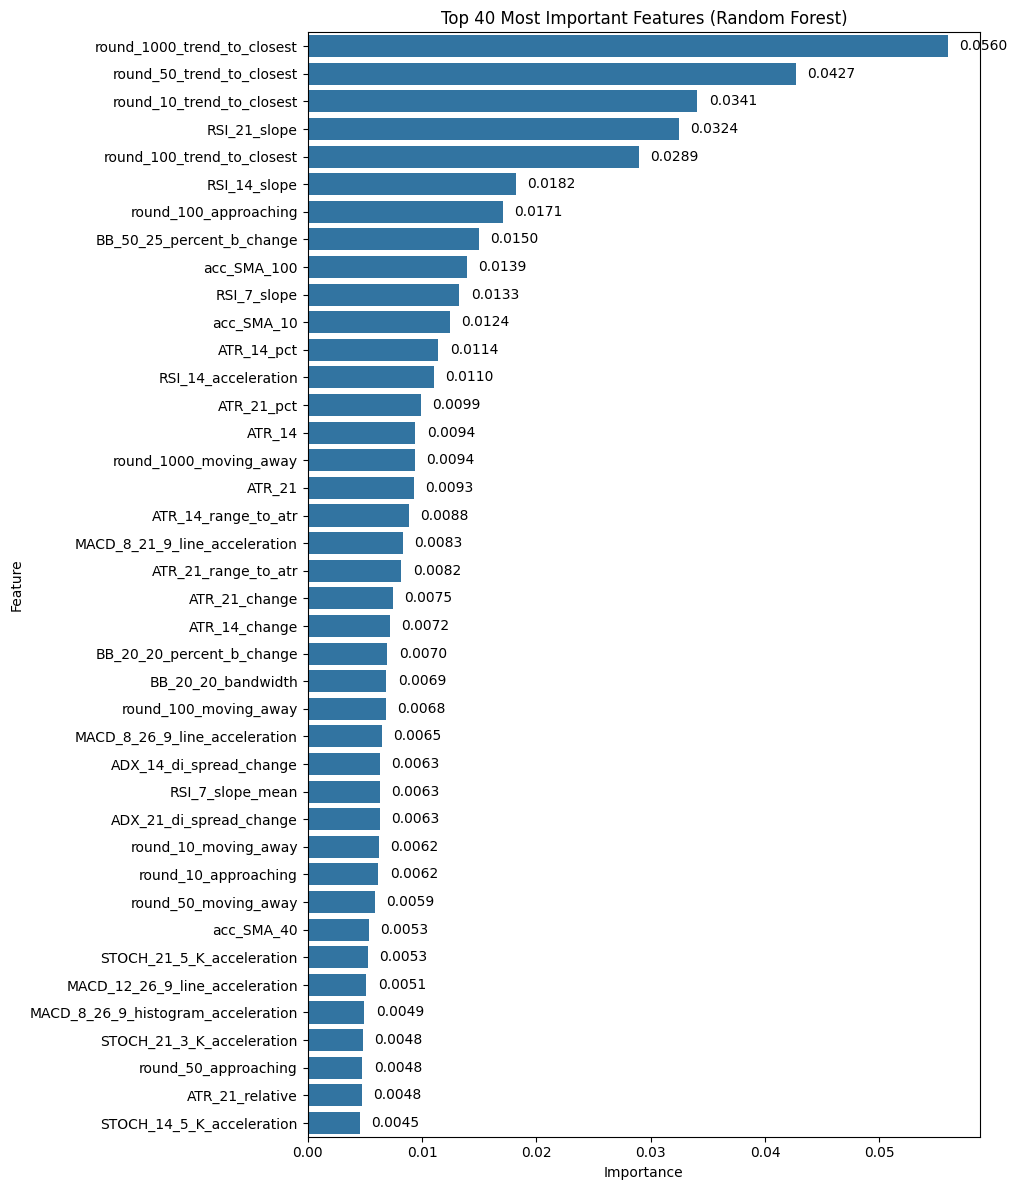

Top 20 features by importance:
                                Feature  Importance
519         round_1000_trend_to_closest    0.055990
483           round_50_trend_to_closest    0.042710
465           round_10_trend_to_closest    0.034079
101                        RSI_21_slope    0.032441
501          round_100_trend_to_closest    0.028932
95                         RSI_14_slope    0.018224
502               round_100_approaching    0.017080
32            BB_50_25_percent_b_change    0.014999
68                          acc_SMA_100    0.013933
98                          RSI_7_slope    0.013274
66                           acc_SMA_10    0.012419
370                          ATR_14_pct    0.011440
97                  RSI_14_acceleration    0.011047
387                          ATR_21_pct    0.009889
369                              ATR_14    0.009420
521              round_1000_moving_away    0.009373
386                              ATR_21    0.009307
384                 ATR_14_range_

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
# Get feature importance from the Random Forest model
importance = rf_model.feature_importances_
feature_names = X_train_final.columns.tolist()

# Create a DataFrame for better sorting and visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

# Select top 20 most important features
top_n = 40
top_features = importance_df.head(top_n)

# Plot the feature importance
plt.figure(figsize=(10, 12))
ax = sns.barplot(x='Importance', y='Feature', data=top_features)
plt.title(f'Top {top_n} Most Important Features (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()

# Add values to the bars
for i, v in enumerate(top_features['Importance']):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center')

plt.show()

# Print the numeric values
print("Top 20 features by importance:")
print(top_features)

In [99]:
y_pred_proba = rf_model.predict_proba(X_test_imputed)

In [100]:
import utils.viz_utils
importlib.reload(utils.viz_utils)

from utils.viz_utils import analizar_metricas_por_umbral

Buy Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,14.19%,"68,917","-24,996",-0.36
1,0.15,14.39%,"67,422","-22,166",-0.33
2,0.20,14.78%,"64,052","-18,153",-0.28
3,0.25,15.44%,"56,322","-13,288",-0.24
4,0.30,16.62%,"41,841","-7,958",-0.19
5,0.35,19.15%,"24,983","-1,234",-0.05
6,0.40,21.83%,"13,499","1,752",0.13
7,0.45,23.80%,"8,438","2,556",0.30
8,0.50,25.82%,"5,526","2,814",0.51
9,0.55,33.07%,"2,422","3,356",1.39



Sell Strategy Metrics:


,threshold,precision,total_trades,profit,avg_pips
0,0.10,13.84%,"69,103","-33,240",-0.48
1,0.15,13.99%,"67,839","-30,616",-0.45
2,0.20,14.27%,"65,295","-26,820",-0.41
3,0.25,14.89%,"59,258","-20,971",-0.35
4,0.30,16.09%,"46,538","-12,938",-0.28
5,0.35,18.29%,"28,745","-4,500",-0.16
6,0.40,21.21%,"15,150",538,0.04
7,0.45,23.24%,"8,947","1,913",0.21
8,0.50,25.69%,"5,571","2,588",0.46
9,0.55,32.17%,"2,543","3,203",1.26


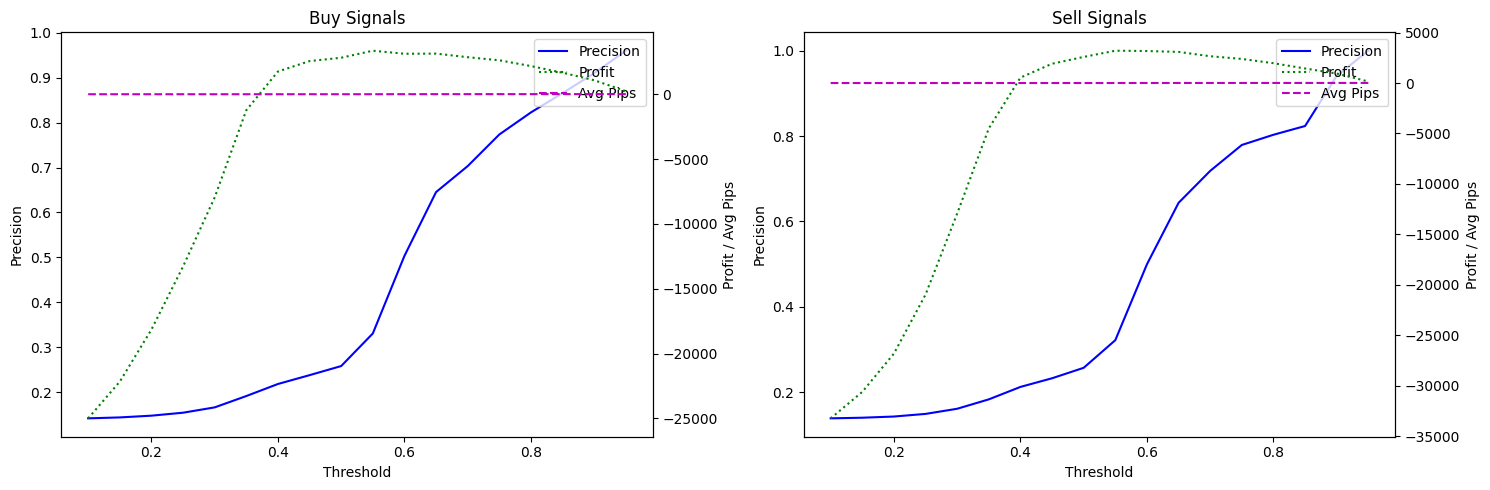


Métricas Mensuales para Compras (Umbral óptimo: 0.55):


,avg_pips,precision,profit,total_trades
month,,,,
2023-01,2.28,40.15%,624,274
2023-02,1.08,30.52%,268,249
2023-03,2.38,41.22%,624,262
2023-04,1.66,34.55%,274,165
2023-05,0.71,28.00%,107,150
2023-06,0.89,29.57%,102,115
2023-07,1.44,33.71%,257,178
2023-08,0.73,28.10%,111,153
2023-09,0.92,29.41%,109,119



Métricas Mensuales para Ventas (Umbral óptimo: 0.55):


,avg_pips,precision,profit,total_trades
month,,,,
2023-01,2.06,38.77%,568,276
2023-02,1.98,37.44%,401,203
2023-03,1.20,32.01%,334,278
2023-04,0.87,28.74%,145,167
2023-05,1.37,33.13%,228,166
2023-06,0.57,27.50%,92,160
2023-07,1.86,37.00%,373,200
2023-08,1.71,35.71%,264,154
2023-09,1.47,33.33%,172,117


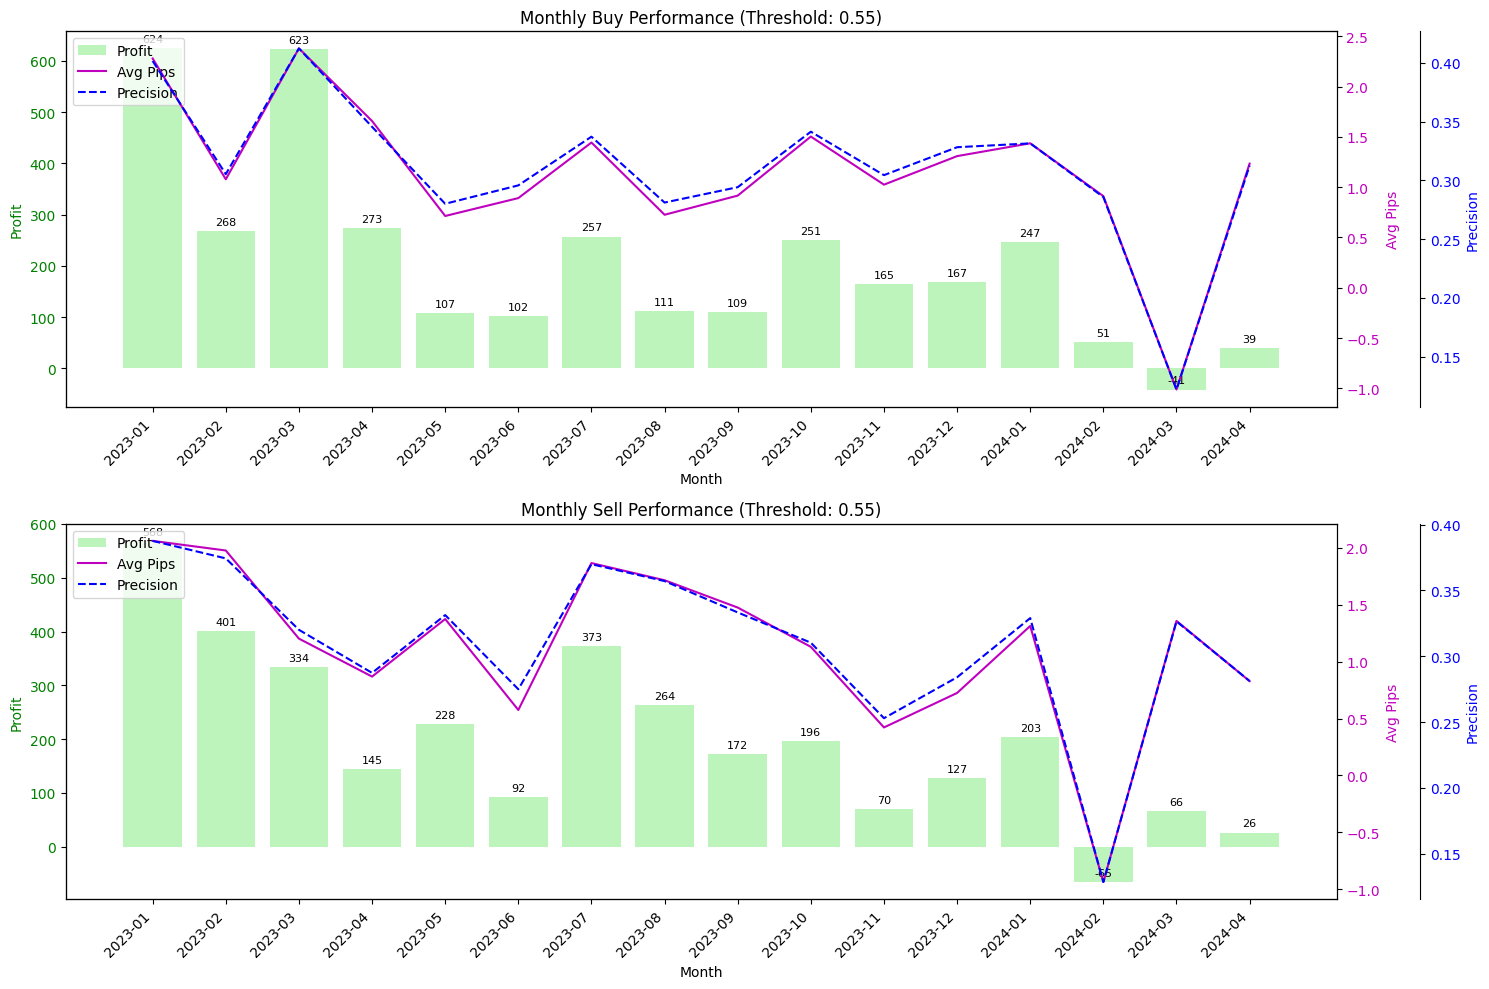


Mejor umbral para compras:
Threshold: 0.55
Profit: 3356
Precision: 33.07%
Avg Pips: 1.39

Mejor umbral para ventas:
Threshold: 0.55
Profit: 3203
Precision: 32.17%
Avg Pips: 1.26

Análisis mensual para compras (umbral 0.70):
Empty DataFrame
Columns: [month, precision, total_trades, profit, avg_pips]
Index: []

Análisis mensual para ventas (umbral 0.70):
Empty DataFrame
Columns: [month, precision, total_trades, profit, avg_pips]
Index: []


In [102]:
# Ejemplo de uso de la nueva versión
compra_df, venta_df, compra_mensual_df, venta_mensual_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=10,
    pip_stop=3
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")
print(f"Avg Pips: {mejor_umbral_compra['avg_pips']:.2f}")  # Nueva métrica

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")
print(f"Avg Pips: {mejor_umbral_venta['avg_pips']:.2f}")  # Nueva métrica

# Análisis mensual para el mejor umbral de compra
umbral_optimo_compra = 0.7
analisis_mensual_compra = compra_mensual_df[compra_mensual_df['threshold'] == umbral_optimo_compra]
print(f"\nAnálisis mensual para compras (umbral {umbral_optimo_compra:.2f}):")
print(analisis_mensual_compra.sort_values('month')[['month', 'precision', 'total_trades', 'profit', 'avg_pips']])

# Análisis mensual para el mejor umbral de venta
umbral_optimo_venta = 0.7
analisis_mensual_venta = venta_mensual_df[venta_mensual_df['threshold'] == umbral_optimo_venta]
print(f"\nAnálisis mensual para ventas (umbral {umbral_optimo_venta:.2f}):")
print(analisis_mensual_venta.sort_values('month')[['month', 'precision', 'total_trades', 'profit', 'avg_pips']])

In [ ]:
import lightgbm as lgb


In [77]:
from sklearn.preprocessing import LabelEncoder
# 1. Preparar los datos
# Codificar la variable objetivo
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


In [65]:
# Definir parámetros para multiclass classification
params = {
    'objective': 'multiclass',
    'num_class': len(le.classes_),
    'metric': 'multi_logloss',
    'verbosity': -1,
    'seed': 42
}

# Create new datasets with encoded labels
lgb_train = lgb.Dataset(X_train_final, y_train_encoded)
lgb_test = lgb.Dataset(X_test_final, y_test_encoded, reference=lgb_train)

# Entrenar el modelo
model = lgb.train(
    params,
    lgb_train,
    valid_sets=[lgb_test]
)

MemoryError: Unable to allocate 5.36 GiB for an array with shape (865269, 831) and data type float64

In [ ]:
# Predecir
y_pred_proba = model.predict(X_test_final)  

In [ ]:
# Convert probabilities to predictions using argmax
y_pred = le.inverse_transform(y_pred_proba.argmax(axis=1))

# Print classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.74      0.99      0.85    120592
objetivo_compra_alcanzado       0.69      0.05      0.10     22107
 objetivo_venta_alcanzado       0.69      0.05      0.09     22106

                 accuracy                           0.74    164805
                macro avg       0.71      0.36      0.34    164805
             weighted avg       0.73      0.74      0.64    164805



Buy Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,16.54%,"121,837","-34,653"
1,0.15,19.22%,"78,117","-7,104"
2,0.20,24.82%,"26,865","11,129"
3,0.25,34.70%,"8,959","14,172"
4,0.30,44.16%,"5,002","13,887"
5,0.35,52.07%,"3,503","13,280"
6,0.40,57.66%,"2,688","12,152"
7,0.45,64.52%,"2,066","11,158"
8,0.50,69.11%,"1,664","9,974"
9,0.55,73.73%,"1,321","8,716"



Sell Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,16.55%,"121,965","-38,484"
1,0.15,19.34%,"69,536","-6,878"
2,0.20,26.02%,"21,896","12,487"
3,0.25,36.32%,"7,779","14,015"
4,0.30,45.29%,"4,504","13,107"
5,0.35,52.90%,"3,159","12,284"
6,0.40,59.37%,"2,358","11,154"
7,0.45,64.92%,"1,873","10,211"
8,0.50,69.17%,"1,492","8,962"
9,0.55,73.28%,"1,149","7,516"


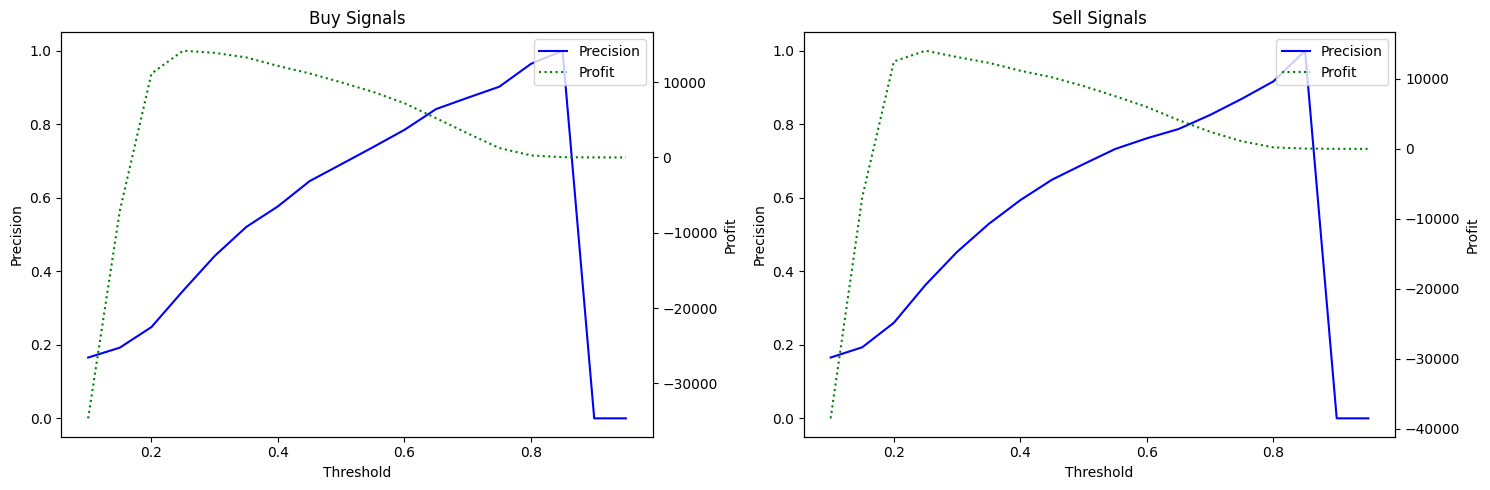


Mejor umbral para compras:
Threshold: 0.25
Profit: 14172
Precision: 34.70%

Mejor umbral para ventas:
Threshold: 0.25
Profit: 14015
Precision: 36.32%


In [ ]:
# Ejemplo de uso
compra_df, venta_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=10,
    pip_stop=3
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")

In [ ]:
# Read Data:
folder_path = '../data/USDJPY/5mins'
df_USDJPY_5min = read_csv_files(folder_path)
df_USDJPY_5min = preprocess_data(df_USDJPY_5min)


In [ ]:
X = 24
# Create sliding window view of future close values
future_high_values = sliding_window_view(df_USDJPY_5min['high'].values, window_shape=X)
future_low_values = sliding_window_view(df_USDJPY_5min['low'].values, window_shape=X)
future_close_values = sliding_window_view(df_USDJPY_5min['close'].values, window_shape=X)

# Pad with NaN at the end since we can't look into the future for the last X-1 rows

padding = np.full((X-1, X), np.nan)
future_high_values = np.vstack([future_high_values, padding])
future_low_values = np.vstack([future_low_values, padding])
future_close_values = np.vstack([future_close_values, padding])

# Assign to DataFrame
df_USDJPY_5min['future_high_values'] = future_high_values.tolist()
df_USDJPY_5min['future_low_values'] = future_low_values.tolist()
df_USDJPY_5min['future_close_values'] = future_close_values.tolist()

# Mostrar las primeras filas para verificar
df_USDJPY_5min.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,future_high_values,future_low_values,future_close_values
0,20100103 17:15:00 US/Eastern,93.075,93.0750,93.0500,93.06,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"[93.075, 93.085, 93.09, 93.0975, 93.09, 93.082...","[93.05, 93.06, 93.0675, 93.06, 93.06, 93.045, ...","[93.06, 93.08, 93.08, 93.09, 93.08, 93.055, 92..."
1,20100103 17:20:00 US/Eastern,93.060,93.0850,93.0600,93.08,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"[93.085, 93.09, 93.0975, 93.09, 93.0825, 93.05...","[93.06, 93.0675, 93.06, 93.06, 93.045, 92.97, ...","[93.08, 93.08, 93.09, 93.08, 93.055, 92.99, 92..."
2,20100103 17:25:00 US/Eastern,93.080,93.0900,93.0675,93.08,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"[93.09, 93.0975, 93.09, 93.0825, 93.055, 93.00...","[93.0675, 93.06, 93.06, 93.045, 92.97, 92.955,...","[93.08, 93.09, 93.08, 93.055, 92.99, 92.96, 92..."
3,20100103 17:30:00 US/Eastern,93.080,93.0975,93.0600,93.09,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"[93.0975, 93.09, 93.0825, 93.055, 93.005, 92.9...","[93.06, 93.06, 93.045, 92.97, 92.955, 92.8925,...","[93.09, 93.08, 93.055, 92.99, 92.96, 92.93, 92..."
4,20100103 17:35:00 US/Eastern,93.090,93.0900,93.0600,93.08,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"[93.09, 93.0825, 93.055, 93.005, 92.965, 92.99...","[93.06, 93.045, 92.97, 92.955, 92.8925, 92.922...","[93.08, 93.055, 92.99, 92.96, 92.93, 92.995, 9..."


In [ ]:
df_resultado[['compra_resultado', 'compra_velas', 'compra_pips',
        'venta_resultado', 'venta_velas', 'venta_pips']] = df_resultado.apply(
    lambda row: evaluar_escenarios_trading(row, pips_objetivo=10, pips_stop=3),
    axis=1
)